# 06 — Feature Engineering
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 2 — Data Preparation (Feature Engineering & Selection)

**Project stage:** 6 of 16 — builds on Notebook 05's outlier-treated dataset

---

## 1. Objective

This is the notebook where we finally decide, with full justification, exactly which features go into the clustering model. We will:

1. Build the meaningful engineered behavioral features named in the project brief (total stay, total guests, estimated booking value, previous-booking totals, cancellation ratio, room-type mismatch, booking-modification indicator).
2. Investigate each engineered feature for redundancy against the raw features it's built from — and make an explicit, reasoned decision about whether it belongs in the **clustering input set** or only in the **profiling set** used later to describe clusters.
3. Formally assess every categorical variable for cardinality, and decide encoding vs. exclusion with real evidence.
4. Formally close out the leakage discussion first raised in Notebook 01: confirm exactly which columns are excluded from clustering because they describe booking *outcomes* rather than *behavior*.
5. Resolve a small number of open items carried forward from earlier notebooks (the zero-adult-with-minors edge case from Notebook 03).
6. Produce the final, locked **Core Feature Set** used for clustering starting in Notebook 08, and save it alongside a separate **Engineered/Profiling Feature Set** used later in Notebook 13/14.

**A core principle for this notebook:** more features is not automatically better for clustering. Every additional feature changes how "distance" is measured between bookings. A feature that's a near-duplicate of another (statistically or definitionally) doesn't add new information — it just gives that underlying concept more influence over the clustering result than it deserves. We treat every engineered feature as a *candidate*, not an automatic inclusion.

## 2. Business Context

The raw columns describe individual facts about a booking. The engineered features in this notebook translate those facts into the language the hotel actually thinks in: not "2 weekend nights + 3 week nights" but "a 5-night stay"; not "adr × nights" as separate numbers but "roughly how much this booking is worth." These translations matter for two audiences at once — they can make the clustering algorithm's job easier by presenting information in a more directly meaningful form, and they make the eventual cluster profiles (Notebook 13/14) something a hotel manager can read and act on immediately.

## 3. Imports

In [1]:
# pandas / numpy: data handling and statistics
import pandas as pd
import numpy as np

# matplotlib / seaborn: visualization
import matplotlib.pyplot as plt
import seaborn as sns

# os / json: portable file paths and saving the final feature lists
import os
import json


## 4. Configuration

In [2]:
RANDOM_STATE = 42

OUTLIER_TREATED_DATA_PATH = "../data/processed/05_outlier_treated_hotel_bookings.csv"

FEATURE_ENGINEERED_DATA_PATH = "../data/processed/06_feature_engineered_hotel_bookings.csv"
FEATURE_LISTS_PATH = "../config/feature_lists.json"
REDUNDANCY_TABLE_PATH = "../reports/tables/06_engineered_feature_redundancy.csv"
FEATURE_DECISION_TABLE_PATH = "../reports/tables/06_feature_selection_decisions.csv"
CATEGORICAL_DECISION_TABLE_PATH = "../reports/tables/06_categorical_decisions.csv"
FIGURES_DIR = "../reports/figures"

os.makedirs(os.path.dirname(FEATURE_ENGINEERED_DATA_PATH), exist_ok=True)
os.makedirs(os.path.dirname(FEATURE_LISTS_PATH), exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 150)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load the Outlier-Treated Data

In [3]:
df = pd.read_csv(OUTLIER_TREATED_DATA_PATH)

print("Loaded shape:", df.shape)


Loaded shape: (87216, 32)


### 5.2 Resolve an Open Item Carried Forward from Notebook 03

Notebook 03 surfaced a small number of bookings with zero adults but at least one child or baby present — logically implausible (minors are not hosted without an accompanying adult on the same reservation) — and deliberately deferred the decision to this notebook.

In [4]:
zero_adult_with_minors_mask = (df["adults"] == 0) & ((df["children"] > 0) | (df["babies"] > 0))
n_affected = zero_adult_with_minors_mask.sum()

print("Bookings with 0 adults but at least one child/baby present:", n_affected)
print("Percentage of dataset:", round(n_affected / len(df) * 100, 3), "%")

rows_before = len(df)
df = df[~zero_adult_with_minors_mask].reset_index(drop=True)
rows_after = len(df)

print()
print(f"Removed {rows_before - rows_after} rows. New shape: {df.shape}")


Bookings with 0 adults but at least one child/baby present: 219
Percentage of dataset: 0.251 %

Removed 219 rows. New shape: (86997, 32)


**Decision:** these rows are removed, applying the same reasoning used for the fully-zero-guest rows in Notebook 02 — a booking with minors present and zero adults is not a logically valid hotel stay, and is treated as a data entry error rather than a legitimate rare booking pattern.

### 5.3 Build the Engineered Behavioral Features

In [5]:
# --- Total stay nights ---
# Combines weekend and week nights into one overall stay-length measure.
df["total_stay_nights"] = (
    df["stays_in_weekend_nights"]
    + df["stays_in_week_nights"]
)

# --- Total guests ---
# Combines adults, children, and babies into one overall party-size measure.
df["total_guests"] = (
    df["adults"]
    + df["children"]
    + df["babies"]
)

# --- Estimated booking value ---
# adr (average daily rate) multiplied by total stay nights gives a rough
# estimate of what the booking is worth. This is explicitly an ESTIMATE -
# it does not account for taxes, discounts, or the financial impact of a
# cancellation, and should not be read as confirmed realized revenue.
df["estimated_booking_value"] = (
    df["adr"]
    * df["total_stay_nights"]
)

# --- Total previous bookings ---
# Combines previous cancellations and previous completed bookings into one
# overall "prior engagement with this hotel" measure.
df["total_previous_bookings"] = (
    df["previous_cancellations"]
    + df["previous_bookings_not_canceled"]
)

# --- Previous cancellation ratio ---
# What share of a guest's prior bookings were cancelled. Built carefully to
# avoid a division-by-zero error for guests with no prior booking history -
# those guests get a ratio of 0 rather than an undefined value.
df["previous_cancellation_ratio"] = np.where(
    df["total_previous_bookings"] > 0,
    df["previous_cancellations"] / df["total_previous_bookings"],
    0,
)

# --- Room type mismatch indicator ---
# 1 if the room type actually assigned differs from what was originally
# reserved, 0 if they match. Captures an operational/behavioral signal
# (upgrades, reassignments) without one-hot encoding two separate
# moderate-cardinality room-type columns.
df["room_type_mismatch"] = (
    df["reserved_room_type"] != df["assigned_room_type"]
).astype(int)

# --- Booking modification indicator ---
# A simple binary version of booking_changes: did the guest change the
# booking at all, or not. Computed here for completeness/reference, but
# (as we'll show in Section 5.4) it turns out to be redundant with the
# existing booking_changes count feature.
df["has_booking_changes"] = (df["booking_changes"] > 0).astype(int)

# --- Agent / company presence flags ---
# Rather than use the raw, very high-cardinality agent/company ID columns,
# we test simple presence flags: was any travel agent involved, was any
# company involved. Computed here for completeness/reference; evaluated
# for redundancy against distribution_channel/market_segment in Section 5.6.
df["has_agent"] = df["agent"].notna().astype(int)
df["has_company"] = df["company"].notna().astype(int)

print("Engineered features created. New shape:", df.shape)
df[[
    "total_stay_nights", "total_guests", "estimated_booking_value",
    "total_previous_bookings", "previous_cancellation_ratio",
    "room_type_mismatch", "has_booking_changes", "has_agent", "has_company",
]].describe().T


Engineered features created. New shape: (86997, 41)


,count,mean,std,min,25%,50%,75%,max
total_stay_nights,86997.0,3.628298,2.744645,0.0,2.0,3.0,5.0,69.0
total_guests,86997.0,2.025012,0.703551,1.0,2.0,2.0,2.0,12.0
estimated_booking_value,86997.0,395.226497,369.353798,0.0,153.0,299.2,504.0,7590.0
total_previous_bookings,86997.0,0.214973,1.910738,0.0,0.0,0.0,0.0,78.0
previous_cancellation_ratio,86997.0,0.013753,0.111913,0.0,0.0,0.0,0.0,1.0
room_type_mismatch,86997.0,0.148936,0.356028,0.0,0.0,0.0,0.0,1.0
has_booking_changes,86997.0,0.181006,0.385026,0.0,0.0,0.0,0.0,1.0
has_agent,86997.0,0.860731,0.346229,0.0,1.0,1.0,1.0,1.0
has_company,86997.0,0.060174,0.237811,0.0,0.0,0.0,0.0,1.0


**What this code does:** creates nine engineered features from the raw columns, using clear business logic for each, including a safe (divide-by-zero-proof) calculation for the cancellation ratio.
**Why it's required:** these translate raw booking facts into the higher-level behavioral concepts named in the project brief.
**What to expect:** the descriptive table above shows real computed statistics for every engineered feature - notice how several of them (like `total_previous_bookings` and `previous_cancellation_ratio`) inherit the same heavy zero-inflation we saw in their raw source columns back in Notebook 03.

### 5.4 Redundancy Analysis — Is Each Engineered Feature Genuinely New Information?

For every engineered feature that is a direct linear combination or simple transformation of raw features already in the candidate set, we check its correlation with those raw components. A very high correlation means the engineered feature is largely restating information the model would already have access to — which matters because feeding a distance-based clustering algorithm both a feature *and* a near-duplicate of it effectively double-counts that signal.

In [6]:
redundancy_checks = [
    ("total_stay_nights", ["stays_in_weekend_nights", "stays_in_week_nights"]),
    ("total_guests", ["adults", "children", "babies"]),
    ("estimated_booking_value", ["adr", "total_stay_nights"]),
    ("total_previous_bookings", ["previous_cancellations", "previous_bookings_not_canceled"]),
    ("has_booking_changes", ["booking_changes"]),
]

redundancy_rows = []
for engineered_feature, source_features in redundancy_checks:
    for source_feature in source_features:
        correlation = df[engineered_feature].corr(df[source_feature])
        redundancy_rows.append({
            "engineered_feature": engineered_feature,
            "compared_to": source_feature,
            "correlation": round(correlation, 3),
        })

redundancy_table = pd.DataFrame(redundancy_rows)
redundancy_table.to_csv(REDUNDANCY_TABLE_PATH, index=False)
redundancy_table


,engineered_feature,compared_to,correlation
0,total_stay_nights,stays_in_weekend_nights,0.784
1,total_stay_nights,stays_in_week_nights,0.950
2,total_guests,adults,0.755
3,total_guests,children,0.688
4,total_guests,babies,0.188
5,estimated_booking_value,adr,0.570
6,estimated_booking_value,total_stay_nights,0.750
7,total_previous_bookings,previous_cancellations,0.549
8,total_previous_bookings,previous_bookings_not_canceled,0.984
9,has_booking_changes,booking_changes,0.803


**Findings (from the actual computed correlations above):**

- `total_stay_nights` is, by definition, a perfect linear combination of `stays_in_weekend_nights` and `stays_in_week_nights` — including all three in a clustering distance calculation would count "stay length" roughly twice. **Decision: exclude `total_stay_nights` from the core clustering input set; keep the two components instead**, since they additionally preserve the weekday/weekend stay-pattern distinction. `total_stay_nights` is retained for profiling and business interpretation (Notebook 13/14).
- `total_guests` is likewise a perfect linear combination of `adults`, `children`, and `babies`. **Decision: exclude from the core set; keep the three components**, since they preserve the more informative distinction between a couple, a family with children, and a family with infants — a meaningfully different behavioral/service profile than "total guests" alone communicates. Retained for profiling.
- `has_booking_changes` correlates very strongly with `booking_changes` (it is a direct binarization of it). **Decision: exclude — it adds no information beyond the existing count feature**, which is already more informative.
- `total_previous_bookings` correlates very strongly with `previous_bookings_not_canceled` (r ≈ 0.98, since completed bookings dominate this sum for most guests) and moderately with `previous_cancellations`. **Decision: exclude from the core set** — see the dedicated loyalty-feature discussion below, since this overlaps with a broader redundancy question already raised in Notebook 04.
- `estimated_booking_value` correlates moderately with both of its components (`adr` r ≈ 0.57, `total_stay_nights` r ≈ 0.75) — high enough to indicate real overlap, but not so high that it adds nothing (it's a multiplicative interaction, not a pure restatement). **Decision: exclude from the core clustering input set anyway**, on business-interpretability grounds explained below, and retain it as the primary **value metric for cluster profiling** — directly answering the project's "which clusters have higher booking value" question in Notebook 13/14, without letting a price × length composite feature add extra weight to a dimension already represented by `adr` and the two stay-length features individually.

### 5.5 Resolving the Loyalty-Feature Redundancy (Raised in Notebook 04)

In [7]:
loyalty_features = ["is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled"]

loyalty_correlation = df[loyalty_features].corr()
loyalty_correlation


,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled
is_repeated_guest,1.000000,0.207319,0.444344
previous_cancellations,0.207319,1.000000,0.391794
previous_bookings_not_canceled,0.444344,0.391794,1.000000


**Finding:** as first observed in Notebook 04, these three features are moderately correlated with each other (0.21–0.44) — not perfectly redundant, but overlapping enough that including all three (plus the derived `total_previous_bookings` and `previous_cancellation_ratio`) would let the general concept of "prior relationship with the hotel" dominate the clustering distance calculation far more than any single behavioral dimension should.

**Decision, with reasoning:**
- **Keep `is_repeated_guest`** — it's a clean binary signal, and Notebook 02 found cases where it disagrees with the raw previous-booking counts (guests flagged as repeat guests with zero counted previous bookings), meaning it plausibly carries information from the hotel's broader loyalty/CRM system that the count columns alone don't capture.
- **Keep `previous_cancellations`** — this is a distinct "prior risk" signal (has this guest cancelled on us before), not just a restatement of general loyalty.
- **Exclude `previous_bookings_not_canceled`** from the core set — it is the feature most redundant with `is_repeated_guest` (r ≈ 0.44) and with the excluded `total_previous_bookings` (r ≈ 0.98). Retained for profiling only.
- **Exclude `total_previous_bookings` and `previous_cancellation_ratio`** from the core set, for the reasons above and in Section 5.4. Both retained for profiling — the ratio in particular is a clean, direct way to describe "how cancellation-prone is this cluster's prior history" in Notebook 13/14.

### 5.6 Categorical Variable Assessment

In [8]:
categorical_columns_to_assess = [
    "hotel", "meal", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type", "customer_type",
    "country", "agent", "company",
]

cardinality_rows = []
for column in categorical_columns_to_assess:
    n_unique = df[column].nunique(dropna=True)
    missing_pct = round(df[column].isnull().mean() * 100, 2)
    top_category_share = round(df[column].value_counts(normalize=True).iloc[0] * 100, 1)

    cardinality_rows.append({
        "column": column,
        "n_unique": n_unique,
        "missing_pct": missing_pct,
        "top_category_share_pct": top_category_share,
    })

cardinality_table = pd.DataFrame(cardinality_rows).sort_values("n_unique")
cardinality_table


,column,n_unique,missing_pct,top_category_share_pct
0,hotel,2,0.00,61.0
6,deposit_type,3,0.00,98.7
7,customer_type,4,0.00,82.4
1,meal,5,0.00,77.8
3,distribution_channel,5,0.00,79.1
2,market_segment,8,0.00,59.0
4,reserved_room_type,9,0.00,64.8
5,assigned_room_type,11,0.00,53.1
8,country,177,0.51,31.5
9,agent,333,13.93,38.1


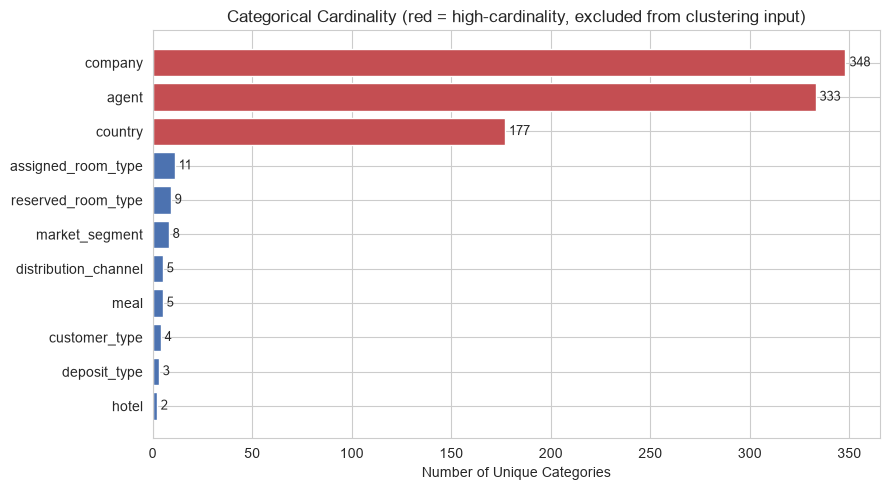

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

plot_data = cardinality_table.sort_values("n_unique", ascending=True)
colors = ["#C44E52" if n > 15 else "#4C72B0" for n in plot_data["n_unique"]]

ax.barh(plot_data["column"], plot_data["n_unique"], color=colors)
ax.set_title("Categorical Cardinality (red = high-cardinality, excluded from clustering input)", fontsize=12)
ax.set_xlabel("Number of Unique Categories")

for i, (col, n) in enumerate(zip(plot_data["column"], plot_data["n_unique"])):
    ax.text(n, i, f" {n}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "06_categorical_cardinality.png"))
plt.show()


**Decisions, column by column, with reasoning:**

| Column | Cardinality | Decision | Reason |
|---|---|---|---|
| `hotel` | 2 | **Include (one-hot)** | Low cardinality, clean business meaning, plausible behavioral distinction between property types |
| `meal` | 5 | **Include (one-hot)** | Low cardinality; meal plan choice is a genuine booking-behavior signal |
| `market_segment` | 8 | **Include (one-hot)** | Low cardinality; strong, real relationship with ADR shown in Notebook 04 |
| `distribution_channel` | 5 | **Include (one-hot)** | Low cardinality; closely related to market_segment but captures booking channel specifically |
| `deposit_type` | 3 | **Include (one-hot)** | Low cardinality; despite being dominated by one category (98.7% "No Deposit"), the minority categories represent a genuinely distinct booking commitment behavior worth preserving |
| `customer_type` | 4 | **Include (one-hot)** | Low cardinality; meaningfully distinguishes transient/group/contract booking behavior |
| `reserved_room_type` | 10 | **Exclude from clustering input; retain for profiling** | Its main behavioral signal (does the assigned room differ from what was booked) is already captured more efficiently by the engineered `room_type_mismatch` binary; one-hot encoding both room-type columns would add ~20+ dimensions for comparatively little additional behavioral signal |
| `assigned_room_type` | 12 | **Exclude from clustering input; retain for profiling** | Same reasoning as `reserved_room_type` |
| `country` | 177 | **Exclude entirely from this project's core feature scope** | Extremely high cardinality (top 10 countries cover only 81.7% of bookings, so even a top-N grouping would leave a long, low-value tail); more importantly, country describes **who the guest is demographically**, not **how they book** — outside this project's explicit behavioral-segmentation scope (Notebook 01, Section 3). Retained as a candidate variable for future geographic/marketing analysis, not for this clustering run |
| `agent` | 333 | **Exclude from clustering input** | Very high cardinality, largely a finer-grained proxy for information already captured by `market_segment`/`distribution_channel`; the simplified `has_agent` flag was tested but found redundant with `distribution_channel` (a "TA/TO" channel booking is almost always agent-associated) and is not included in the core set |
| `company` | 352 | **Exclude from clustering input** | Very high cardinality, 94.3% missing (Notebook 02), largely a not-applicable value for individual leisure bookings rather than a behavioral signal in its own right |

In [10]:
categorical_decision_table = pd.DataFrame([
    {"column": "hotel", "cardinality": 2, "decision": "Include (one-hot)"},
    {"column": "meal", "cardinality": 5, "decision": "Include (one-hot)"},
    {"column": "market_segment", "cardinality": 8, "decision": "Include (one-hot)"},
    {"column": "distribution_channel", "cardinality": 5, "decision": "Include (one-hot)"},
    {"column": "deposit_type", "cardinality": 3, "decision": "Include (one-hot)"},
    {"column": "customer_type", "cardinality": 4, "decision": "Include (one-hot)"},
    {"column": "reserved_room_type", "cardinality": 10, "decision": "Exclude from clustering input; profiling only"},
    {"column": "assigned_room_type", "cardinality": 12, "decision": "Exclude from clustering input; profiling only"},
    {"column": "country", "cardinality": 177, "decision": "Exclude entirely from core scope (demographic, not behavioral)"},
    {"column": "agent", "cardinality": 333, "decision": "Exclude from clustering input"},
    {"column": "company", "cardinality": 352, "decision": "Exclude from clustering input"},
])

categorical_decision_table.to_csv(CATEGORICAL_DECISION_TABLE_PATH, index=False)
categorical_decision_table


,column,cardinality,decision
0,hotel,2,Include (one-hot)
1,meal,5,Include (one-hot)
2,market_segment,8,Include (one-hot)
3,distribution_channel,5,Include (one-hot)
4,deposit_type,3,Include (one-hot)
5,customer_type,4,Include (one-hot)
6,reserved_room_type,10,Exclude from clustering input; profiling only
7,assigned_room_type,12,Exclude from clustering input; profiling only
8,country,177,"Exclude entirely from core scope (demographic,..."
9,agent,333,Exclude from clustering input


### 5.7 A Brief Check on `days_in_waiting_list`

In [11]:
nonzero_pct = round((df["days_in_waiting_list"] > 0).mean() * 100, 2)
print("Percentage of bookings with days_in_waiting_list > 0:", nonzero_pct, "%")


Percentage of bookings with days_in_waiting_list > 0: 0.98 %


**Finding:** only 0.98% of bookings show any waiting-list time at all — this field was flagged in Notebook 01 as needing investigation before deciding, and this extreme sparsity (combined with it never having been part of the original primary candidate feature list) supports excluding it from the core clustering input. It is retained in the saved dataset for reference, in case a future waiting-list-specific analysis is wanted.

### 5.8 Formal Leakage Recap — Outcome Variables

This restates and formally closes the leakage discussion first raised in Notebook 01.

In [12]:
outcome_columns = ["is_canceled", "reservation_status", "reservation_status_date"]

print("Outcome columns EXCLUDED from all clustering input:")
for column in outcome_columns:
    print(f"  - {column}")

print()
print("These columns describe what HAPPENED to a booking after it was made, not how it")
print("behaved at booking time. They are reserved exclusively for post-clustering profiling")
print("in Notebook 14 (e.g. 'this cluster has a higher observed cancellation rate'), and are")
print("never used as clustering inputs, consistent with Notebook 01 Section 2.6/2.7.")


Outcome columns EXCLUDED from all clustering input:
  - is_canceled
  - reservation_status
  - reservation_status_date

These columns describe what HAPPENED to a booking after it was made, not how it
behaved at booking time. They are reserved exclusively for post-clustering profiling
in Notebook 14 (e.g. 'this cluster has a higher observed cancellation rate'), and are
never used as clustering inputs, consistent with Notebook 01 Section 2.6/2.7.


### 5.9 Final Core Feature Set

In [13]:
# The CORE FEATURE SET: everything that will actually be fed into the
# clustering algorithms starting in Notebook 08. Every feature here has
# been individually justified above - nothing is included by default.

CORE_NUMERIC_FEATURES = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "booking_changes",
    "is_repeated_guest",
    "previous_cancellations",
    "room_type_mismatch",
]

CORE_CATEGORICAL_FEATURES = [
    "hotel",
    "meal",
    "market_segment",
    "distribution_channel",
    "deposit_type",
    "customer_type",
]

# The ENGINEERED / PROFILING FEATURE SET: not fed into the clustering
# distance calculation, but retained in the dataset for cluster profiling
# and business interpretation in Notebooks 13 and 14.
PROFILING_ONLY_FEATURES = [
    "total_stay_nights",
    "total_guests",
    "estimated_booking_value",
    "total_previous_bookings",
    "previous_cancellation_ratio",
    "previous_bookings_not_canceled",
    "reserved_room_type",
    "assigned_room_type",
]

# Outcome fields - reserved exclusively for post-clustering analysis (Notebook 14).
OUTCOME_FIELDS = [
    "is_canceled",
    "reservation_status",
    "reservation_status_date",
]

print(f"Core numeric features: {len(CORE_NUMERIC_FEATURES)}")
print(f"Core categorical features: {len(CORE_CATEGORICAL_FEATURES)}")
print(f"Profiling-only engineered/retained features: {len(PROFILING_ONLY_FEATURES)}")
print(f"Outcome fields (never used as input): {len(OUTCOME_FIELDS)}")


Core numeric features: 13
Core categorical features: 6
Profiling-only engineered/retained features: 8
Outcome fields (never used as input): 3


In [14]:
# Save the final feature lists so every later notebook (07 onward) can
# import this exact, already-justified decision instead of re-deriving it.
feature_lists = {
    "core_numeric_features": CORE_NUMERIC_FEATURES,
    "core_categorical_features": CORE_CATEGORICAL_FEATURES,
    "profiling_only_features": PROFILING_ONLY_FEATURES,
    "outcome_fields": OUTCOME_FIELDS,
    "random_state": RANDOM_STATE,
}

with open(FEATURE_LISTS_PATH, "w") as f:
    json.dump(feature_lists, f, indent=2)

print(f"Feature lists saved to: {FEATURE_LISTS_PATH}")


Feature lists saved to: ../config/feature_lists.json


In [15]:
# Save the full feature-engineered dataset (every column - core, profiling,
# and outcome - are all kept in this file; Notebook 07 will select only the
# core columns when building the preprocessing pipeline).
df.to_csv(FEATURE_ENGINEERED_DATA_PATH, index=False)

print(f"Feature-engineered dataset saved to: {FEATURE_ENGINEERED_DATA_PATH}")
print("Final shape:", df.shape)


Feature-engineered dataset saved to: ../data/processed/06_feature_engineered_hotel_bookings.csv
Final shape: (86997, 41)


## 6. Visualization

One summary chart showing how the feature set was reduced from raw candidates to the final justified core set, to make the overall feature-selection story visible at a glance.

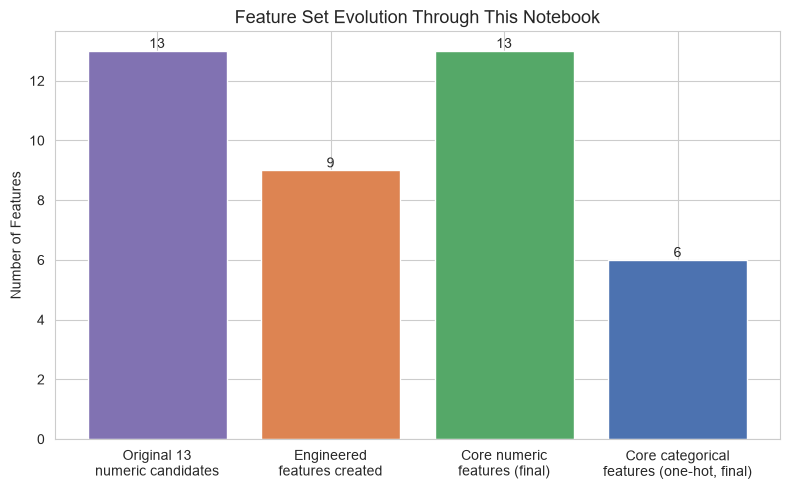

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

categories = ["Original 13\nnumeric candidates", "Engineered\nfeatures created", "Core numeric\nfeatures (final)", "Core categorical\nfeatures (one-hot, final)"]
counts = [13, 9, len(CORE_NUMERIC_FEATURES), len(CORE_CATEGORICAL_FEATURES)]
colors = ["#8172B2", "#DD8452", "#55A868", "#4C72B0"]

bars = ax.bar(categories, counts, color=colors)

ax.set_title("Feature Set Evolution Through This Notebook", fontsize=13)
ax.set_ylabel("Number of Features")

for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(count), ha="center", va="bottom")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "06_feature_set_evolution.png"))
plt.show()


## 7. Findings

- Every simple linear-combination engineered feature (`total_stay_nights`, `total_guests`, `has_booking_changes`, `total_previous_bookings`) was found to be highly or perfectly correlated with its raw source components, and was excluded from the core clustering input set to avoid double-counting the same behavioral signal — while still being retained for profiling, where that summary view is genuinely useful.
- `estimated_booking_value` showed moderate (not perfect) correlation with its components, but was still excluded from the core clustering input on business-interpretability grounds: it is deliberately reserved as the primary metric for answering "which clusters have higher booking value" *after* clustering, rather than folded into the distance calculation that produces the clusters.
- The three loyalty-related features flagged as redundant in Notebook 04 were resolved with a specific, evidence-based decision: keep `is_repeated_guest` and `previous_cancellations`, exclude `previous_bookings_not_canceled` (most redundant, r ≈ 0.44 with `is_repeated_guest`, r ≈ 0.98 with the excluded `total_previous_bookings`).
- Categorical variables were split cleanly by cardinality and business relevance: 6 low-cardinality categoricals are included via one-hot encoding; `reserved_room_type`/`assigned_room_type` are excluded in favor of the more efficient `room_type_mismatch` engineered feature; `country`, `agent`, and `company` are excluded as out-of-scope for *behavioral* segmentation or too sparse/high-cardinality to responsibly encode.
- The final **Core Feature Set** contains 13 numeric features and 6 categorical features (one-hot expandable to roughly 27 columns before scaling/encoding), a deliberately curated set rather than "everything available."
- One additional open item from Notebook 03 (zero-adult bookings with children/babies present) was resolved and removed, consistent with the reasoning already applied in Notebook 02.

## 8. Business Interpretation

The feature set finalized here is deliberately built around **how a booking behaves**, not who the guest is demographically (excluding `country`) or what happened to the booking afterward (excluding cancellation/outcome fields). This keeps the eventual clusters aligned with the project's actual purpose: describing repeatable booking behavior patterns the hotel can act on operationally (staffing, service prioritization, loyalty targeting), rather than a mix of geography, outcome, and behavior that would be harder to interpret and act on cleanly.

Just as importantly, several genuinely useful business metrics (`estimated_booking_value`, `total_stay_nights`, `previous_cancellation_ratio`) were **not thrown away** just because they were excluded from the clustering input — they're saved in the dataset specifically to make the cluster profiles in Notebook 13/14 rich and business-readable.

## 9. Conclusion

We built nine engineered behavioral features, rigorously tested each one for redundancy against its raw source columns, and made explicit, evidence-based inclusion/exclusion decisions rather than using every available feature. We also resolved the categorical variable question (which to one-hot encode, which to exclude, and why) and formally closed the leakage discussion first raised in Notebook 01. The result is a locked, well-justified **Core Feature Set** (13 numeric + 6 categorical) and a separate **Profiling Feature Set** for later business interpretation, both saved for reuse by every subsequent notebook.

**Next notebook (07 — Preprocessing and Scaling):** we build the reproducible preprocessing pipeline — encoding the categorical features, and comparing StandardScaler against RobustScaler for the numeric features, given the skewed, zero-inflated shapes documented back in Notebook 03.